In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving heart_disease_dataset.csv to heart_disease_dataset.csv


In [ ]:
df = pd.read_csv("heart_disease_dataset.csv")

df.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,heart_disease
0,58,1,1,134,246,0,0,155,0,0.4,1,1,2,1
1,52,0,2,112,245,0,0,143,1,0.1,0,0,3,1
2,59,0,2,126,196,0,0,162,1,1.1,1,0,1,1
3,67,1,1,165,201,0,0,180,0,0.4,2,0,2,0
4,51,1,0,146,174,1,1,133,1,0.9,1,1,2,1


In [ ]:
df.shape

(400, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      400 non-null    int64  
 1   sex                      400 non-null    int64  
 2   chest_pain_type          400 non-null    int64  
 3   resting_blood_pressure   400 non-null    int64  
 4   cholesterol              400 non-null    int64  
 5   fasting_blood_sugar      400 non-null    int64  
 6   resting_ecg              400 non-null    int64  
 7   max_heart_rate           400 non-null    int64  
 8   exercise_induced_angina  400 non-null    int64  
 9   st_depression            400 non-null    float64
 10  st_slope                 400 non-null    int64  
 11  num_major_vessels        400 non-null    int64  
 12  thalassemia              400 non-null    int64  
 13  heart_disease            400 non-null    int64  
dtypes: float64(1), int64(13)
m

In [ ]:
df.describe()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,heart_disease
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.00000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,53.667500,0.662500,1.712500,123.630000,216.627500,0.140000,0.530000,146.717500,0.29250,0.753250,1.177500,0.677500,1.925000,0.555000
std,8.508403,0.473449,1.035628,16.567114,41.379941,0.347422,0.533678,21.104293,0.45548,0.772841,0.645784,0.889084,0.689611,0.497588
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,91.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,1.000000,112.000000,188.000000,0.000000,0.000000,132.000000,0.00000,0.200000,1.000000,0.000000,2.000000,0.000000
50%,54.000000,1.000000,2.000000,124.000000,216.000000,0.000000,1.000000,146.000000,0.00000,0.600000,1.000000,0.000000,2.000000,1.000000
75%,59.000000,1.000000,3.000000,135.000000,246.000000,0.000000,1.000000,161.000000,1.00000,0.900000,2.000000,1.000000,2.000000,1.000000
max,77.000000,1.000000,3.000000,174.000000,336.000000,1.000000,2.000000,202.000000,1.00000,4.900000,2.000000,3.000000,3.000000,1.000000


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
chest_pain_type,0
resting_blood_pressure,0
cholesterol,0
fasting_blood_sugar,0
resting_ecg,0
max_heart_rate,0
exercise_induced_angina,0
st_depression,0


In [ ]:
df["heart_disease"].value_counts()

,count
heart_disease,
1,222
0,178


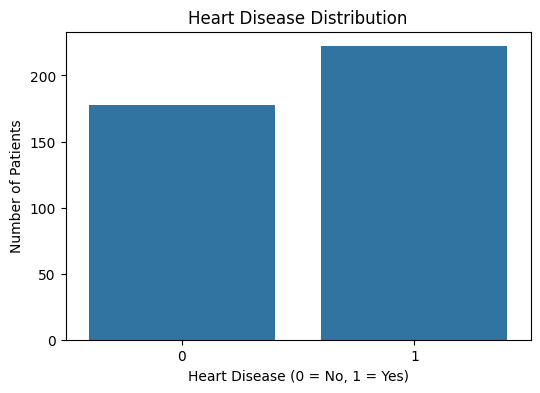

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="heart_disease")
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()

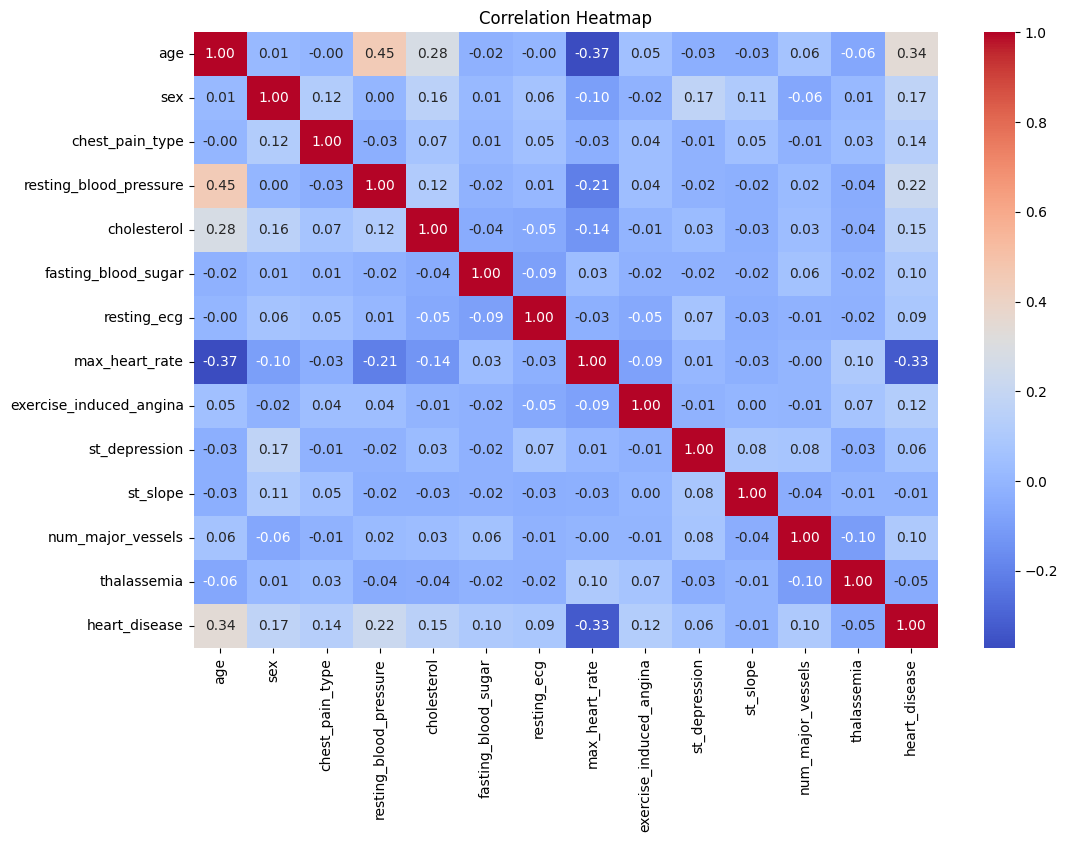

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
X = df.drop("heart_disease", axis=1)
y = df["heart_disease"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (400, 13)
Target shape: (400,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42,stratify=y)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

In [ ]:
models["Random Forest"] = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [ ]:
models["Logistic Regression"] = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [ ]:
models["SVM"] = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

In [ ]:
for name, model in models.items():
    model.fit(X_train, y_train)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [ ]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

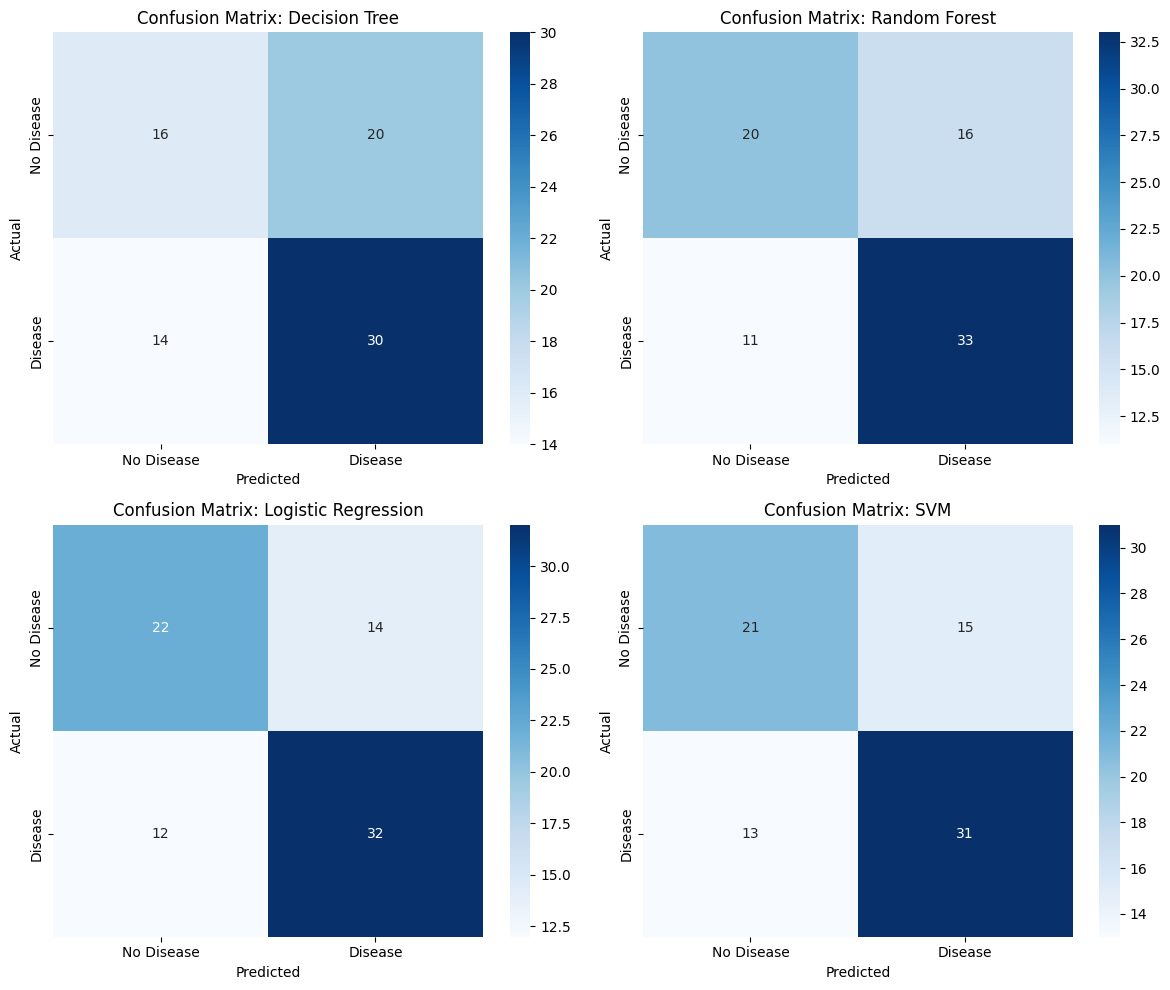

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, (name, model) in enumerate(models.items()):
    y_pred_model = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred_model)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[idx], xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")
    axes[idx].set_title(f"Confusion Matrix: {name}")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.62      0.58      0.60        36
           1       0.67      0.70      0.69        44

    accuracy                           0.65        80
   macro avg       0.65      0.64      0.64        80
weighted avg       0.65      0.65      0.65        80



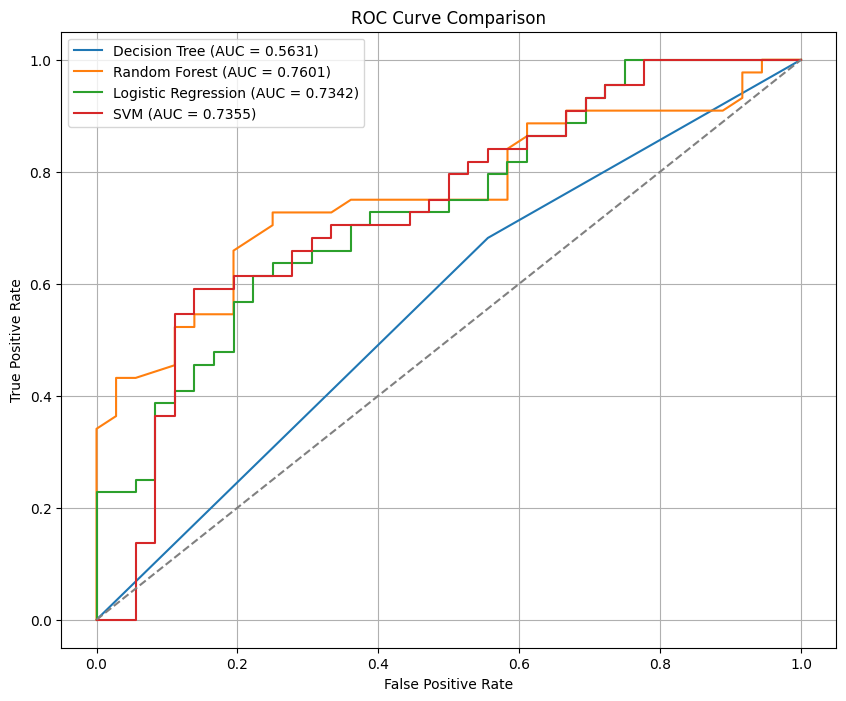

In [ ]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_prob_model = model.predict_proba(X_test)[:, 1]
    else:
        y_prob_model = model.decision_function(X_test)

    fpr, tpr, _ = roc_curve(y_test, y_prob_model)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

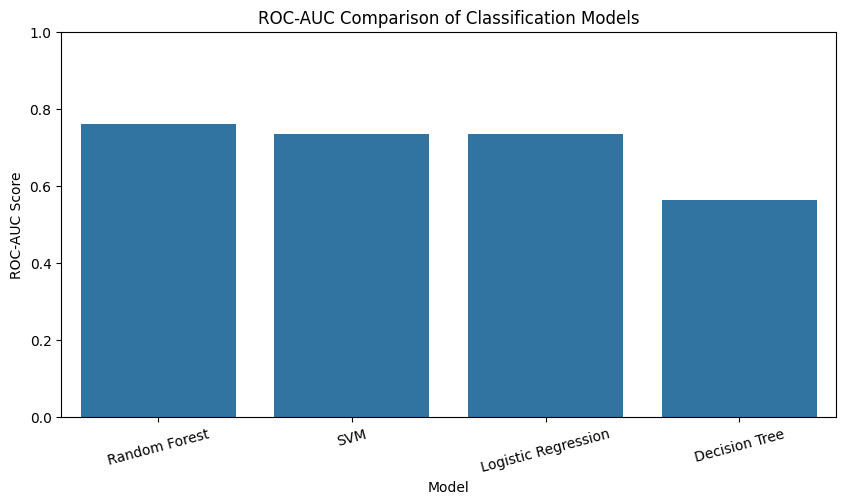

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC-AUC"
)

plt.title("ROC-AUC Comparison of Classification Models")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
print("Best model based on ROC-AUC:", best_model_name)

Best model based on ROC-AUC: Random Forest


In [ ]:
y_pred = best_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Heart Disease", "Heart Disease"],
    zero_division=0
))

                  precision    recall  f1-score   support

No Heart Disease       0.65      0.56      0.60        36
   Heart Disease       0.67      0.75      0.71        44

        accuracy                           0.66        80
       macro avg       0.66      0.65      0.65        80
    weighted avg       0.66      0.66      0.66        80



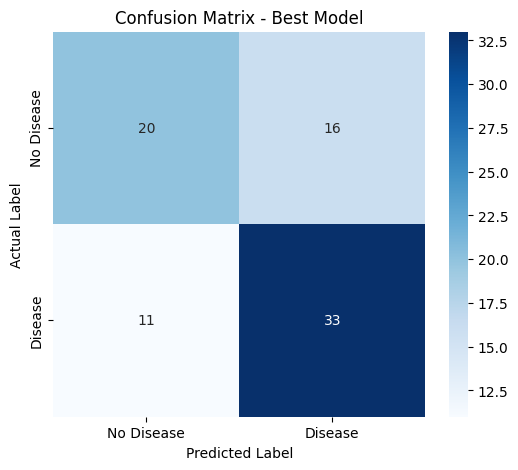

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.title("Confusion Matrix - Best Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

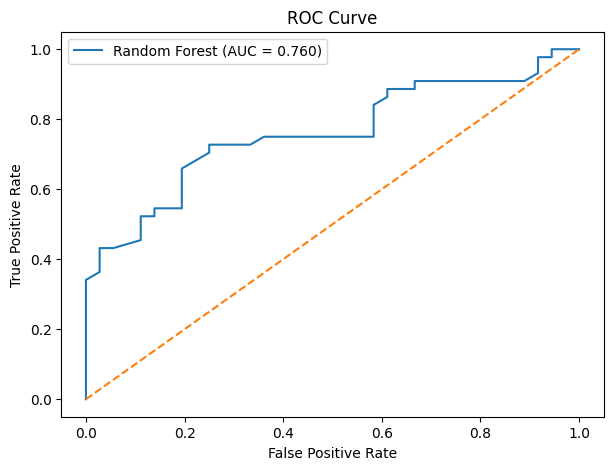

In [ ]:
y_prob = best_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name} (AUC = {auc_score:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

,Feature,Importance
7,max_heart_rate,0.177015
0,age,0.149207
4,cholesterol,0.139503
3,resting_blood_pressure,0.130215
9,st_depression,0.108214
2,chest_pain_type,0.058367
11,num_major_vessels,0.049893
1,sex,0.045325
10,st_slope,0.036956
12,thalassemia,0.034337


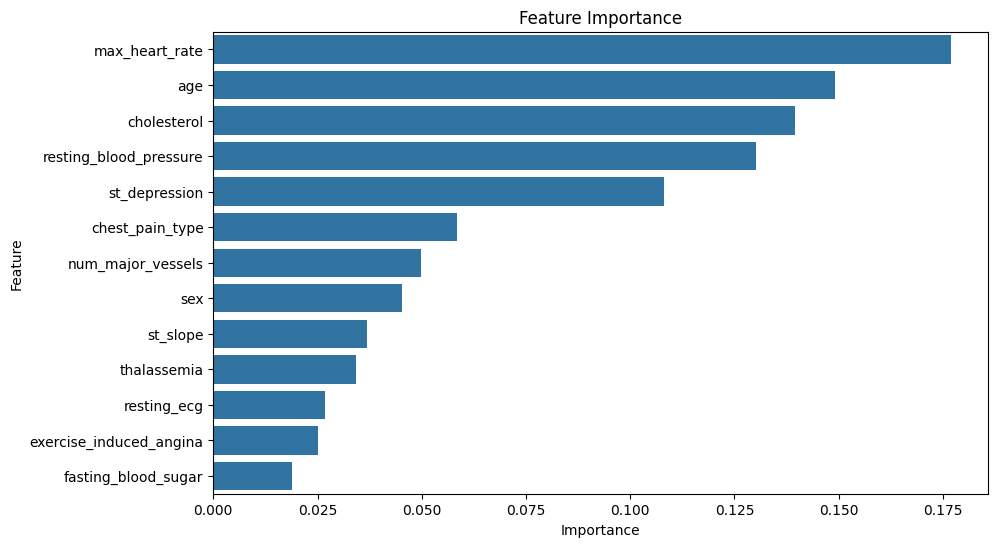

In [ ]:
if best_model_name in ["Decision Tree", "Random Forest"]:

    importance = best_model.feature_importances_

    feature_importance = pd.DataFrame({
        "Feature": X.columns,
        "Importance": importance
    })

    feature_importance = feature_importance.sort_values(
        by="Importance",
        ascending=False
    )

    display(feature_importance)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=feature_importance,
        x="Importance",
        y="Feature"
    )

    plt.title("Feature Importance")
    plt.show()

In [ ]:
import joblib

joblib.dump(
    best_model,
    "heart_disease_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files
files.download("heart_disease_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
results_df.to_csv(
    "heart_disease_model_comparison.csv",
    index=False
)
from google.colab import files
files.download("heart_disease_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
patient_data = {
    "age": 55,
    "sex": 1,
    "chest_pain_type": 2,
    "resting_blood_pressure": 130,
    "cholesterol": 250,
    "fasting_blood_sugar": 0,
    "resting_ecg": 1,
    "max_heart_rate": 150,
    "exercise_induced_angina": 0,
    "st_depression": 1.0,
    "st_slope": 1,
    "num_major_vessels": 0,
    "thalassemia": 2
}
patient_df = pd.DataFrame([patient_data])
prediction = model.predict(patient_df)[0]
print("Predicted class:", prediction)

Predicted class: 1
